# 01 · Data audit: TB chest X-rays

**Goal:** decide whether the dataset can be trusted *before* any EDA or training.

| # | Check | Question it answers |
|---|---|---|
| 1 | Inventory | How many images per class? Is it imbalanced? |
| 2 | Integrity | Are any files corrupt? Are colour modes consistent? |
| 3 | Size & metadata | Do image sizes, aspect ratios or DPI differ **by class**? |
| 4 | Exact duplicates | Are there byte-identical copies that could leak across splits? |
| 5 | Near-duplicates | Are there resized/recompressed copies MD5 can't see? |
| 6 | Pixel statistics | Do the classes differ in brightness/contrast (scanner/source effects)? |
| 7 | Shortcut test | Can the label be predicted from **metadata alone**, without the anatomy? |

All logic lives in `src/pipeline/data_audit.py`; this notebook runs it and adds plots.
Run it from VS Code with the `tb_v2_env` kernel selected.

In [1]:
# --- Setup: run from the repo root so paths in config.yaml and splits.csv work ---
import os, sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:   # notebook may start in notebooks/
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown

from src.pipeline import data_audit as da

pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Repo root:", ROOT)

Repo root: d:\Guvi\Projects\mini\Tuberculosis Detection Using Deep Learning\tuberculosis-detection-v2


In [2]:
# --- Dataset location (default: data_path from config.yaml) ---
DATA_DIR = None          # or e.g. "data/Dataset of Tuberculosis Chest X-rays Images"
OUT_DIR = "reports/data_audit"

if DATA_DIR is None:
    from src.utils.config_loader import load_config
    DATA_DIR = load_config()["data_path"]
os.makedirs(OUT_DIR, exist_ok=True)
DATA_DIR

'data/Dataset of Tuberculosis Chest X-rays Images'

In [3]:
# --- Scan every file once (takes ~1-2 min for 3,000 images on CPU) ---
df, classes, skipped = da.build_inventory(DATA_DIR)
ok = df[df["readable"]].copy()
print(f"{len(df)} image files, {len(skipped)} non-image files skipped, classes: {classes}")
df.drop(columns="dhash").head()

3008 image files, 0 non-image files skipped, classes: ['Normal Chest X-rays', 'TB Chest X-rays']


,path,class,ext,file_kb,readable,error,width,height,mode,format,dpi,mean_px,std_px,dark_frac,bright_frac,md5,label,aspect,size_wxh
0,data/Dataset of Tuberculosis Chest X-rays Images/Normal Chest X-rays/others ...,Normal Chest X-rays,.jpg,11.399414,True,,256,256,RGB,JPEG,,145.046143,54.272999,0.015869,0.000000,a155ebdbd18b502e62d0747f3b9f74fb,0,1.0,256x256
1,data/Dataset of Tuberculosis Chest X-rays Images/Normal Chest X-rays/others ...,Normal Chest X-rays,.jpg,9.585938,True,,256,256,RGB,JPEG,,141.646240,43.790340,0.000244,0.000000,5b9277e3ce4ce588dd0cd15f4969a450,0,1.0,256x256
2,data/Dataset of Tuberculosis Chest X-rays Images/Normal Chest X-rays/others ...,Normal Chest X-rays,.jpg,8.844727,True,,256,256,RGB,JPEG,,126.710205,45.834522,0.000977,0.000000,4fafb0f7baf46201c340f4262ca1ebaa,0,1.0,256x256
3,data/Dataset of Tuberculosis Chest X-rays Images/Normal Chest X-rays/others ...,Normal Chest X-rays,.jpg,10.357422,True,,256,256,RGB,JPEG,,134.184814,49.971207,0.002441,0.000244,47e2e40ef7638887965aacdc15814692,0,1.0,256x256
4,data/Dataset of Tuberculosis Chest X-rays Images/Normal Chest X-rays/others ...,Normal Chest X-rays,.jpg,8.670898,True,,256,256,RGB,JPEG,,123.881836,44.825546,0.000977,0.000244,043a2bdeb789cb6c28bb4084597c43b7,0,1.0,256x256


## 1. Inventory and class balance
Label mapping is alphabetical (the same order Keras uses), so the first folder is label 0.

,label,files,share_%
Normal Chest X-rays,0,514,17.1
TB Chest X-rays,1,2494,82.9


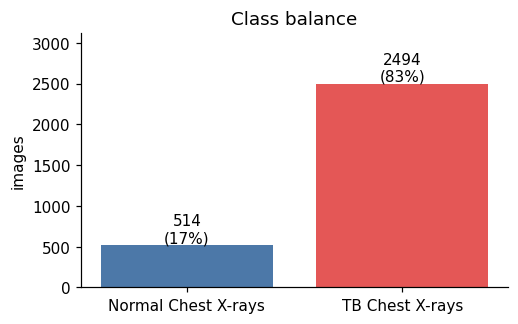

In [4]:
counts = df["class"].value_counts().reindex(classes)
display(pd.DataFrame({"label": range(len(classes)), "files": counts.values,
                      "share_%": (100 * counts / counts.sum()).round(1).values}, index=classes))

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(counts.index, counts.values, color=["#4C78A8", "#E45756"][:len(counts)])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v}\n({100*v/counts.sum():.0f}%)", ha="center", va="bottom")
ax.set_ylabel("images"); ax.set_title("Class balance"); ax.margins(y=0.25)
plt.show()
if skipped:
    print("Skipped non-image files:", skipped)

**What to note:** a strong imbalance changes how you evaluate (accuracy becomes misleading; use sensitivity/specificity and ROC-AUC) and suggests class weights or stratified splits.

## 2. Integrity: corrupt files and colour modes

In [5]:
bad = df[~df["readable"]]
print(f"Unreadable / corrupt files: {len(bad)}")
display(bad[["path", "error"]]) if len(bad) else None
display(pd.crosstab(ok["class"], ok["mode"]))

Unreadable / corrupt files: 0


mode,RGB
class,
Normal Chest X-rays,514
TB Chest X-rays,2494


**What to note:** mixed modes (e.g. some `L` grayscale, some `RGB`) mean every loader and the app must call `.convert("RGB")`.

## 3. Image size, aspect ratio and DPI per class

class,Normal Chest X-rays,TB Chest X-rays
size_wxh,,
256x256,514,2370
256x215,0,8
256x217,0,7
256x213,0,6
256x203,0,5
256x225,0,5
256x221,0,5
256x219,0,5
256x209,0,5


class,Normal Chest X-rays,TB Chest X-rays
dpi,,
,514,2370
"(96, 96)",0,124


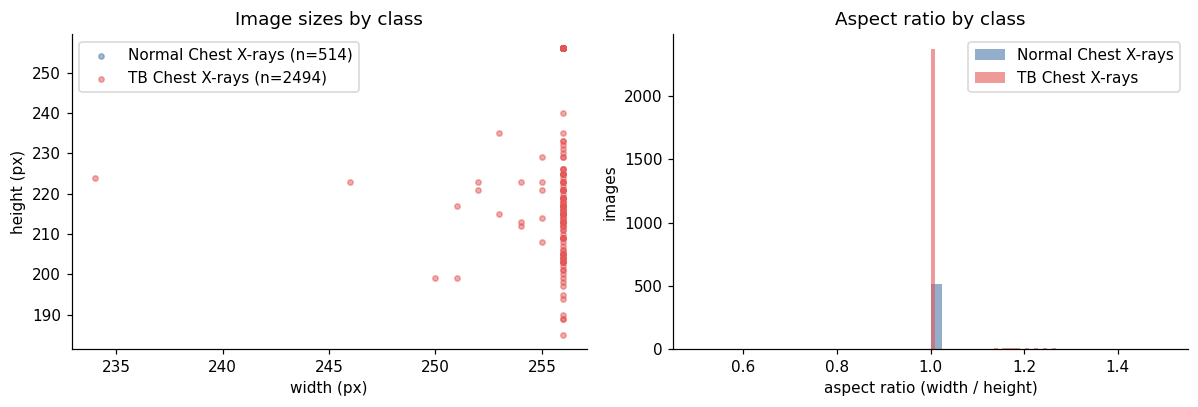

In [6]:
display(pd.crosstab(ok["size_wxh"], ok["class"]).sort_values(classes[-1], ascending=False).head(10))
display(pd.crosstab(ok["dpi"], ok["class"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for cls, color in zip(classes, ["#4C78A8", "#E45756"]):
    sub = ok[ok["class"] == cls]
    axes[0].scatter(sub["width"], sub["height"], s=12, alpha=0.5, label=f"{cls} (n={len(sub)})", color=color)
    axes[1].hist(sub["aspect"], bins=40, alpha=0.6, label=cls, color=color)
axes[0].set(xlabel="width (px)", ylabel="height (px)", title="Image sizes by class")
axes[1].set(xlabel="aspect ratio (width / height)", ylabel="images", title="Aspect ratio by class")
axes[0].legend(); axes[1].legend()
plt.tight_layout(); plt.show()

In [7]:
# Which images are not the most common size? Show a few per class.
common = ok["size_wxh"].mode()[0]
odd = ok[ok["size_wxh"] != common]
print(f"Most common size: {common}.  Images with another size: "
      f"{odd['class'].value_counts().to_dict()}")

Most common size: 256x256.  Images with another size: {'TB Chest X-rays': 124}


**What to note:** if one class has sizes or aspect ratios the other never has, resizing everything to 224×224 stretches only that class, and a CNN can learn the stretching instead of the disease. **Measure sizes with Pillow, as here**: tools like `file` print DPI as "density 96x96", which is easy to misread as pixel size.

## 4. Exact duplicates (MD5 hash of the file bytes)

In [8]:
dups, cross = da.exact_duplicates(df)
n_groups = dups["group"].nunique() if len(dups) else 0
print(f"Files in duplicate groups: {len(dups)} ({n_groups} groups). "
      f"Groups spanning two classes (label conflicts): {cross}")
display(dups.head(10))

Files in duplicate groups: 52 (26 groups). Groups spanning two classes (label conflicts): 0


,group,md5,class,path
2694,0,0451cb0f392b5832186f47dd94571084,TB Chest X-rays,data/Dataset of Tuberculosis Chest X-rays Images/TB Chest X-rays/TB.716.jpg
2701,0,0451cb0f392b5832186f47dd94571084,TB Chest X-rays,data/Dataset of Tuberculosis Chest X-rays Images/TB Chest X-rays/TB.722.jpg
2682,1,0c08041f4c8b5caf2b8d9a1a6edb6147,TB Chest X-rays,data/Dataset of Tuberculosis Chest X-rays Images/TB Chest X-rays/TB.705.jpg
2736,1,0c08041f4c8b5caf2b8d9a1a6edb6147,TB Chest X-rays,data/Dataset of Tuberculosis Chest X-rays Images/TB Chest X-rays/TB.754.jpg
2680,2,0c9f539e919e9965596b1d3973c5c6d9,TB Chest X-rays,data/Dataset of Tuberculosis Chest X-rays Images/TB Chest X-rays/TB.703.jpg
2726,2,0c9f539e919e9965596b1d3973c5c6d9,TB Chest X-rays,data/Dataset of Tuberculosis Chest X-rays Images/TB Chest X-rays/TB.745.jpg
2689,3,0ce075ba47b80030274521d34da3bcff,TB Chest X-rays,data/Dataset of Tuberculosis Chest X-rays Images/TB Chest X-rays/TB.711.jpg
2695,3,0ce075ba47b80030274521d34da3bcff,TB Chest X-rays,data/Dataset of Tuberculosis Chest X-rays Images/TB Chest X-rays/TB.717.jpg
2643,4,252ad2d01cffa5a1b37d6da1c4d10bf8,TB Chest X-rays,data/Dataset of Tuberculosis Chest X-rays Images/TB Chest X-rays/TB.670.jpg
2666,4,252ad2d01cffa5a1b37d6da1c4d10bf8,TB Chest X-rays,data/Dataset of Tuberculosis Chest X-rays Images/TB Chest X-rays/TB.691.jpg


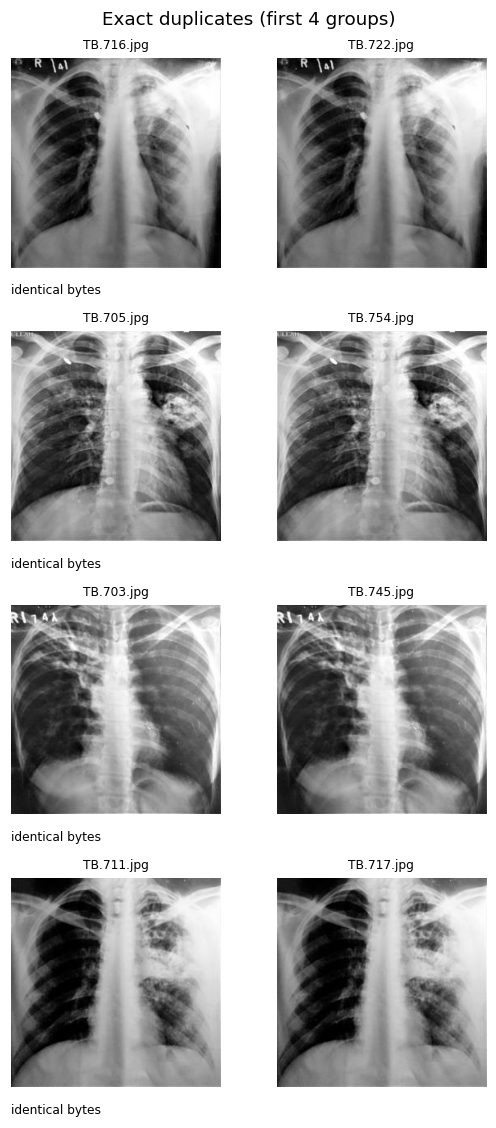

In [9]:
def show_pairs(pairs, title, n=4):
    """pairs: list of (path_a, path_b, caption)"""
    pairs = pairs[:n]
    if not pairs:
        print("Nothing to show."); return
    fig, axes = plt.subplots(len(pairs), 2, figsize=(5, 2.6 * len(pairs)), squeeze=False)
    for row, (a, b, cap) in zip(axes, pairs):
        for ax, p in zip(row, (a, b)):
            ax.imshow(Image.open(p).convert("L"), cmap="gray"); ax.axis("off")
            ax.set_title(os.path.basename(p), fontsize=8)
        row[0].text(0, -0.08, cap, transform=row[0].transAxes, fontsize=8, va="top")
    fig.suptitle(title); plt.tight_layout(); plt.show()

exact_pairs = [(g.iloc[0]["path"], g.iloc[1]["path"], "identical bytes")
               for _, g in dups.groupby("group")] if len(dups) else []
show_pairs(exact_pairs, "Exact duplicates (first 4 groups)")

**What to note:** every duplicate must be removed **before** splitting, otherwise one copy can land in train and the other in test, inflating test scores. A duplicate in *both* classes is a label conflict: one label is wrong.

## 5. Near-duplicates (perceptual hash, catches resized or recompressed copies)

Near-duplicate candidate pairs (Hamming distance <= 4): 22138; cross-class: 4200


,path_a,class_a,path_b,class_b,hamming
13052,data/Dataset of Tuberculosis Chest X-rays Images/Normal Chest X-rays/others ...,Normal Chest X-rays,data/Dataset of Tuberculosis Chest X-rays Images/Normal Chest X-rays/others ...,Normal Chest X-rays,0
15278,data/Dataset of Tuberculosis Chest X-rays Images/Normal Chest X-rays/others ...,Normal Chest X-rays,data/Dataset of Tuberculosis Chest X-rays Images/Normal Chest X-rays/others ...,Normal Chest X-rays,0
9036,data/Dataset of Tuberculosis Chest X-rays Images/Normal Chest X-rays/others ...,Normal Chest X-rays,data/Dataset of Tuberculosis Chest X-rays Images/Normal Chest X-rays/others ...,Normal Chest X-rays,0
1041,data/Dataset of Tuberculosis Chest X-rays Images/Normal Chest X-rays/others ...,Normal Chest X-rays,data/Dataset of Tuberculosis Chest X-rays Images/Normal Chest X-rays/others ...,Normal Chest X-rays,0
3450,data/Dataset of Tuberculosis Chest X-rays Images/Normal Chest X-rays/others ...,Normal Chest X-rays,data/Dataset of Tuberculosis Chest X-rays Images/Normal Chest X-rays/others ...,Normal Chest X-rays,0
10930,data/Dataset of Tuberculosis Chest X-rays Images/Normal Chest X-rays/others ...,Normal Chest X-rays,data/Dataset of Tuberculosis Chest X-rays Images/Normal Chest X-rays/others ...,Normal Chest X-rays,0
17709,data/Dataset of Tuberculosis Chest X-rays Images/TB Chest X-rays/TB.1059.jpg,TB Chest X-rays,data/Dataset of Tuberculosis Chest X-rays Images/TB Chest X-rays/TB.874.jpg,TB Chest X-rays,0
21865,data/Dataset of Tuberculosis Chest X-rays Images/TB Chest X-rays/TB.727.jpg,TB Chest X-rays,data/Dataset of Tuberculosis Chest X-rays Images/TB Chest X-rays/TB.798.jpg,TB Chest X-rays,0
6835,data/Dataset of Tuberculosis Chest X-rays Images/Normal Chest X-rays/others ...,Normal Chest X-rays,data/Dataset of Tuberculosis Chest X-rays Images/Normal Chest X-rays/others ...,Normal Chest X-rays,0
4106,data/Dataset of Tuberculosis Chest X-rays Images/Normal Chest X-rays/others ...,Normal Chest X-rays,data/Dataset of Tuberculosis Chest X-rays Images/Normal Chest X-rays/others ...,Normal Chest X-rays,0


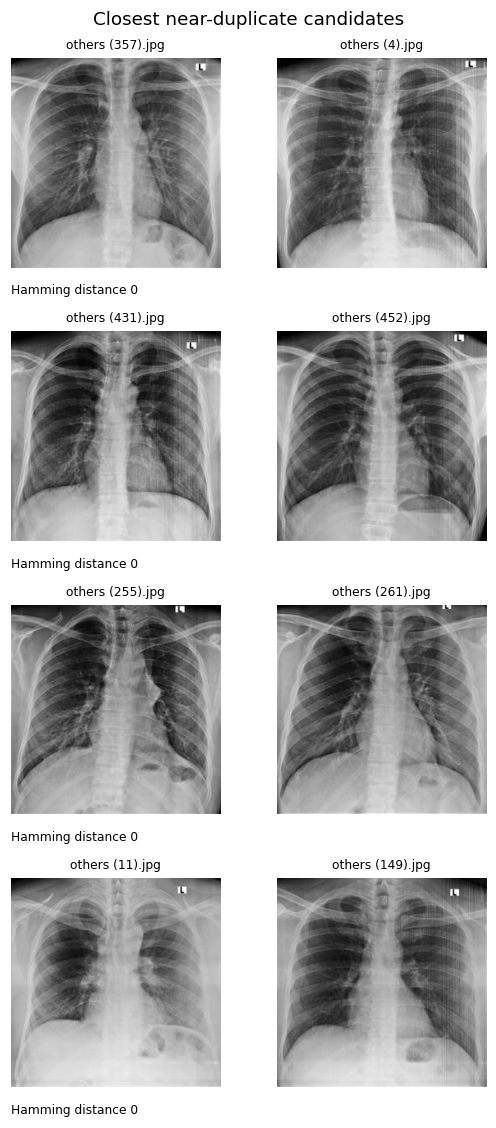

In [10]:
near = da.near_duplicates(df)
print(f"Near-duplicate candidate pairs (Hamming distance <= {da.NEAR_DUP_BITS}): {len(near)}; "
      f"cross-class: {int((near['class_a'] != near['class_b']).sum()) if len(near) else 0}")
display(near.sort_values("hamming").head(10))
show_pairs([(r.path_a, r.path_b, f"Hamming distance {r.hamming}") for r in near.sort_values("hamming").itertuples()],
           "Closest near-duplicate candidates")

**What to note:** these are **candidates**. Chest X-rays look alike, so look at the pairs yourself before removing anything. Distance 0–2 is almost always the same image.

## 6. Pixel statistics per class (64×64 grayscale thumbnails)

,mean_px,std_px,dark_frac,bright_frac
class,,,,
Normal Chest X-rays,132.841995,48.298000,0.004,0.000
TB Chest X-rays,135.744995,53.796001,0.010,0.006


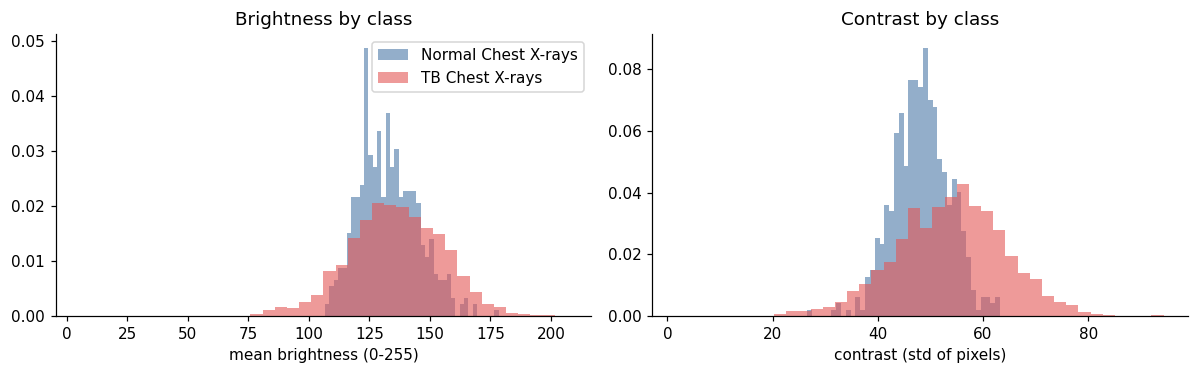

In [11]:
stats = ["mean_px", "std_px", "dark_frac", "bright_frac"]
display(ok.groupby("class")[stats].mean().round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for cls, color in zip(classes, ["#4C78A8", "#E45756"]):
    sub = ok[ok["class"] == cls]
    axes[0].hist(sub["mean_px"], bins=40, alpha=0.6, label=cls, color=color, density=True)
    axes[1].hist(sub["std_px"], bins=40, alpha=0.6, label=cls, color=color, density=True)
axes[0].set(xlabel="mean brightness (0-255)", title="Brightness by class")
axes[1].set(xlabel="contrast (std of pixels)", title="Contrast by class")
axes[0].legend(); plt.tight_layout(); plt.show()

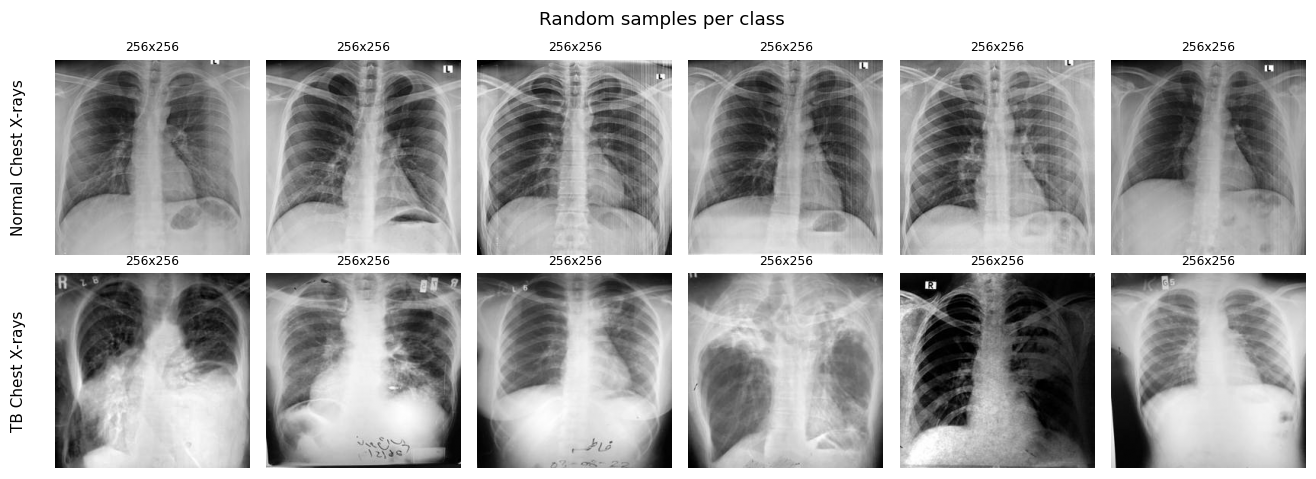

In [12]:
# Random samples per class: look for borders, text markers, different scanners
rng = np.random.default_rng(42)
fig, axes = plt.subplots(len(classes), 6, figsize=(12, 2.2 * len(classes)), squeeze=False)
for row, cls in zip(axes, classes):
    paths = ok[ok["class"] == cls]["path"].values
    for ax, p in zip(row, rng.choice(paths, size=min(6, len(paths)), replace=False)):
        im = Image.open(p)
        ax.imshow(im.convert("L"), cmap="gray"); ax.axis("off")
        ax.set_title(f"{im.width}x{im.height}", fontsize=8)
    row[0].text(-0.15, 0.5, cls, transform=row[0].transAxes, rotation=90, va="center", ha="right")
plt.suptitle("Random samples per class"); plt.tight_layout(); plt.show()

**What to note:** look for things a model could use that aren't disease: borders, letters/markers, different cropping, different exposure. If you see them in one class only, write them down as a shortcut risk.

## 7. Shortcut test: predict the label from metadata only

,features,model,roc_auc_mean,roc_auc_std
0,width + height + aspect,logistic regression,0.525,0.002
1,width + height + aspect,decision tree (depth 3),0.525,0.002
2,file size (KB),logistic regression,0.784,0.018
3,file size (KB),decision tree (depth 3),0.861,0.015
4,brightness/contrast,logistic regression,0.744,0.007
5,brightness/contrast,decision tree (depth 3),0.803,0.013
6,all metadata,logistic regression,0.911,0.019
7,all metadata,decision tree (depth 3),0.918,0.014


Best metadata-only ROC-AUC: 0.918  (all metadata, decision tree (depth 3))


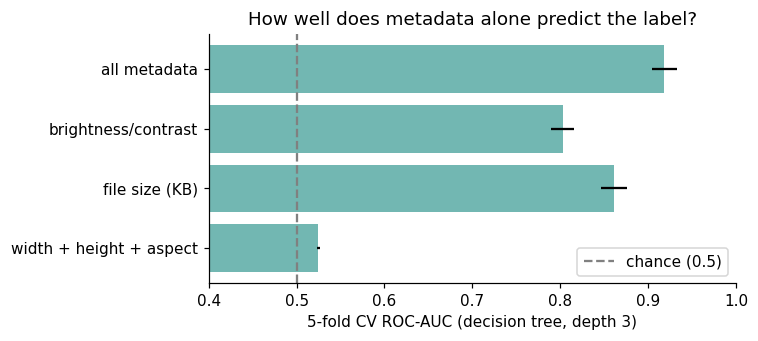

In [13]:
shortcut = da.shortcut_test(df)
if shortcut is None:
    print("Shortcut test only implemented for 2 classes.")
else:
    display(shortcut.round(3))
    best = shortcut.loc[shortcut["roc_auc_mean"].idxmax()]
    print(f"Best metadata-only ROC-AUC: {best.roc_auc_mean:.3f}  ({best.features}, {best.model})")

    fig, ax = plt.subplots(figsize=(7, 3.2))
    lr = shortcut[shortcut["model"].str.startswith("decision")]
    ax.barh(lr["features"], lr["roc_auc_mean"], xerr=lr["roc_auc_std"], color="#72B7B2")
    ax.axvline(0.5, color="grey", ls="--", label="chance (0.5)")
    ax.set(xlim=(0.4, 1.0), xlabel="5-fold CV ROC-AUC (decision tree, depth 3)",
           title="How well does metadata alone predict the label?")
    ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

**How to read this:**
- **≈ 0.5:** metadata says nothing about the label. Good.
- **0.6–0.8:** some collection difference between classes. Report it and test the CNN on the affected subgroup.
- **≥ 0.9:** the classes can be told apart **without looking at the lungs**. Any high CNN accuracy is suspect until you show it holds on images that don't have the shortcut.

## Save outputs and summary

In [14]:
df.drop(columns="dhash").to_csv(f"{OUT_DIR}/inventory.csv", index=False)
dups.to_csv(f"{OUT_DIR}/exact_duplicates.csv", index=False)
near.to_csv(f"{OUT_DIR}/near_duplicates.csv", index=False)
report = da.write_report(OUT_DIR, DATA_DIR, df, classes, skipped, dups, cross, near, shortcut)

summary = f"""
| Check | Result |
|---|---|
| Images | {len(df)} ({', '.join(f'{c}: {n}' for c, n in counts.items())}) |
| Corrupt files | {len(bad)} |
| Exact-duplicate files | {len(dups)} in {n_groups} groups, {cross} cross-class |
| Near-duplicate candidates | {len(near)} pairs |
| Sizes differing from {common} | {odd['class'].value_counts().to_dict()} |
| Best metadata-only ROC-AUC | {shortcut['roc_auc_mean'].max():.3f} |
""" if shortcut is not None else ""
display(Markdown(summary))
print("Saved:", report)


| Check | Result |
|---|---|
| Images | 3008 (Normal Chest X-rays: 514, TB Chest X-rays: 2494) |
| Corrupt files | 0 |
| Exact-duplicate files | 52 in 26 groups, 0 cross-class |
| Near-duplicate candidates | 22138 pairs |
| Sizes differing from 256x256 | {'TB Chest X-rays': 124} |
| Best metadata-only ROC-AUC | 0.918 |


Saved: reports/data_audit\report.md


## Conclusions (fill in after running)

- **Class balance:** …
- **Duplicates:** … → handled in `make_splits.py` (exact). Near-duplicates: …
- **Size/source shortcut:** … (metadata-only ROC-AUC = …)
- **Decisions for training:** …
- **Limitations to report:** no patient IDs, so patient-level splitting is impossible; …